<a href="https://colab.research.google.com/github/aba90-ship-it/labor-market-trends-analysis/blob/main/ProjectWages.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install fredapi pandas matplotlib scipy statsmodels seaborn

In [ ]:
import sys
!{sys.executable} -m pip install fredapi pandas matplotlib scipy statsmodels seaborn

Fetching series from FRED...
  wages (CES0500000003): 246 observations
  cpi (CPIAUCSL): 956 observations
  unemployment (UNRATE): 944 observations
  pce (PCEPI): 811 observations

--- Correlation Matrix ---
                  wage_growth_yoy  inflation_yoy  unemployment  \
wage_growth_yoy             1.000          0.496        -0.343   
inflation_yoy               0.496          1.000        -0.429   
unemployment               -0.343         -0.429         1.000   
real_wage_growth            0.112         -0.807         0.258   

                  real_wage_growth  
wage_growth_yoy              0.112  
inflation_yoy               -0.807  
unemployment                 0.258  
real_wage_growth             1.000  

--- Multiple Regression: Wage Growth ~ Inflation + Unemployment ---
                            OLS Regression Results                            
Dep. Variable:        wage_growth_yoy   R-squared:                       0.267
Model:                            OLS   Adj. R-sq

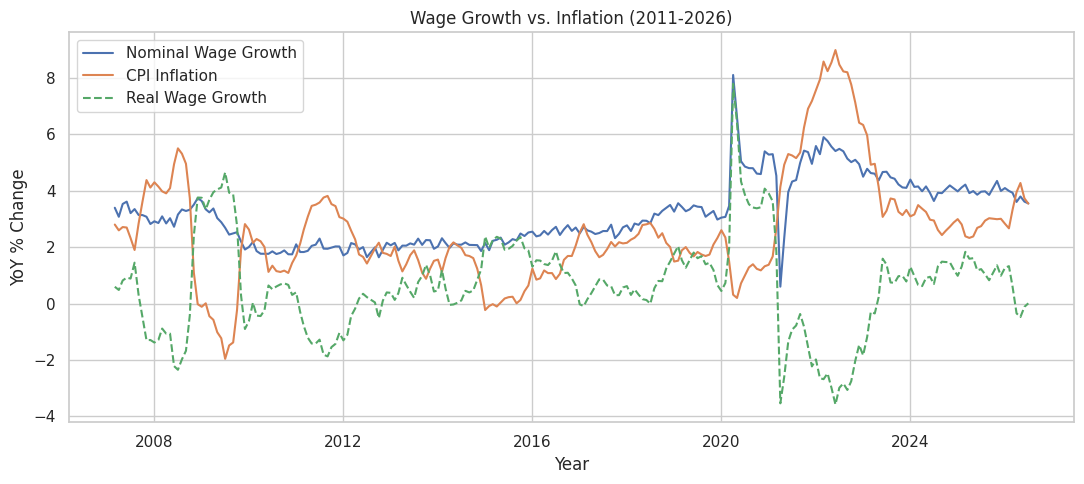

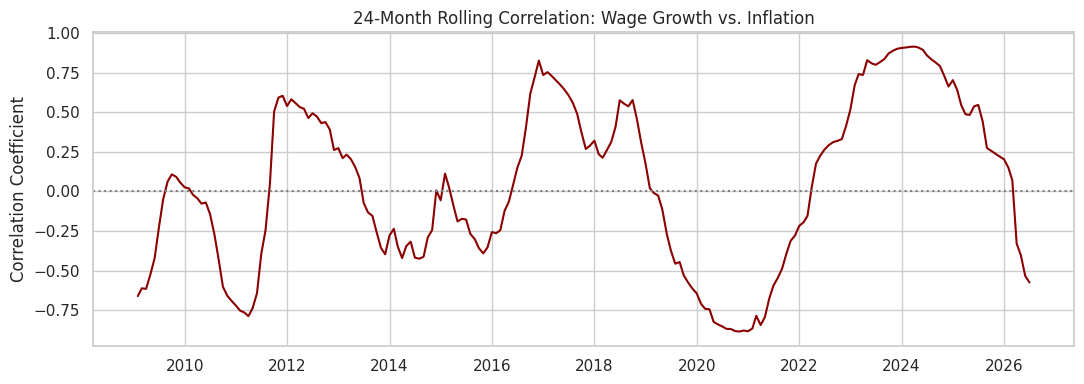

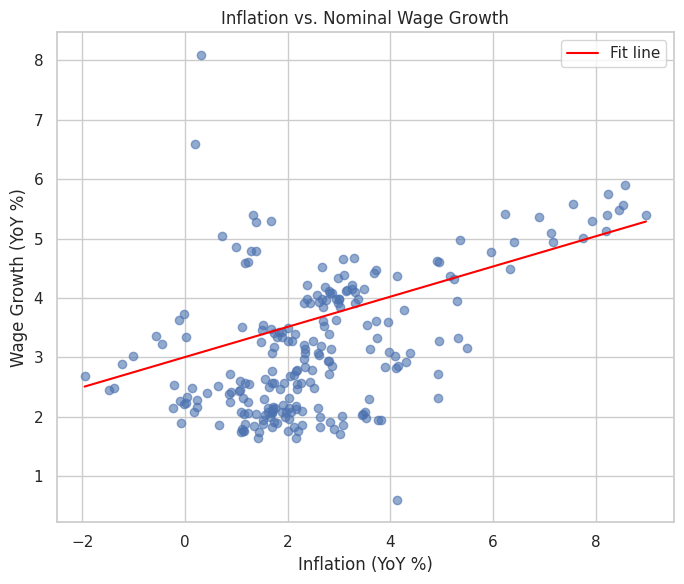

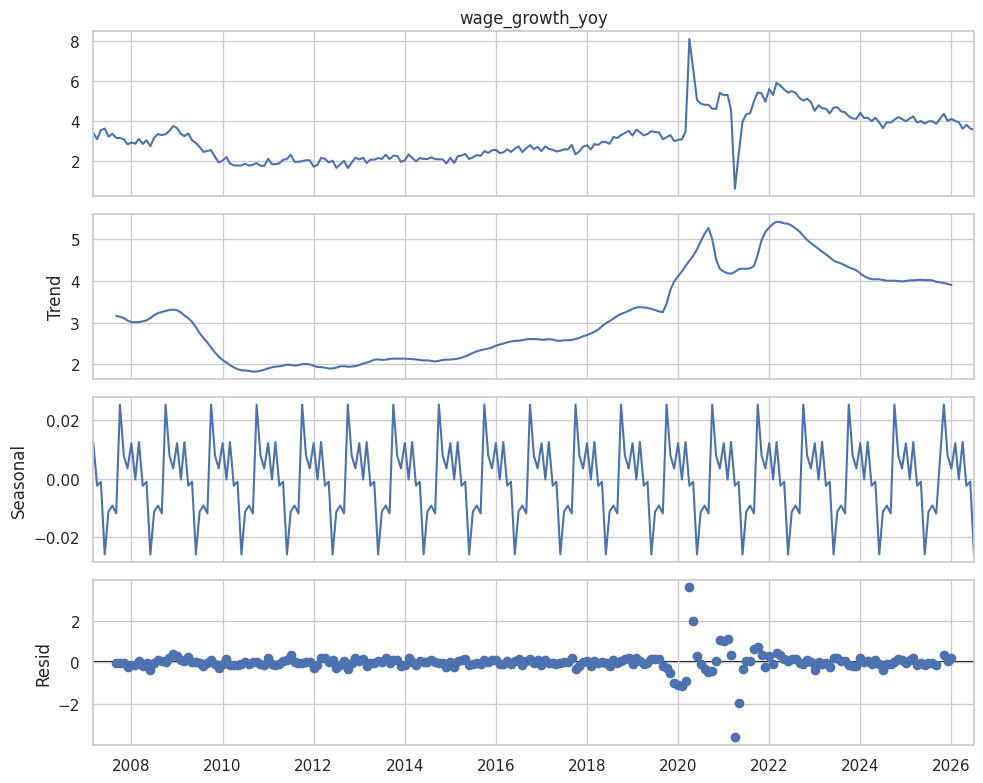

In [ ]:
"""
Labor Market Trends Analysis: Wages, Inflation, and Unemployment
------------------------------------------------------------------
A multi-indicator analysis of U.S. labor market dynamics using FRED data.

Analysis includes:
- Nominal and real wage growth trends
- Correlation and multiple regression (inflation + unemployment -> wage growth)
- Rolling correlation to see how the relationship shifts over time
- Seasonal decomposition of wage growth
- Summary statistics and visualizations

SETUP:
1. pip install fredapi pandas matplotlib scipy statsmodels seaborn
2. Paste your FRED API key below
3. Run: python labor_market_analysis.py
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from fredapi import Fred
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose

# ============================================================
# 1. CONFIGURATION
# ============================================================
FRED_API_KEY = "YOUR_KEY_HERE"
START_DATE = "2011-01-01"
END_DATE = "2026-01-01"

SERIES = {
    "wages": "CES0500000003",       # Average Hourly Earnings, Total Private
    "cpi": "CPIAUCSL",              # Consumer Price Index
    "unemployment": "UNRATE",       # Unemployment Rate
    "pce": "PCEPI",                 # Personal Consumption Expenditures Price Index
}

sns.set_theme(style="whitegrid")


class LaborMarketAnalyzer:
    """Pulls FRED labor market data and runs a multi-indicator analysis."""

    def __init__(self, api_key, series_map, start, end):
        self.fred = Fred(api_key=api_key)
        self.series_map = series_map
        self.start = start
        self.end = end
        self.raw = pd.DataFrame()
        self.data = pd.DataFrame()

    # -------------------- DATA COLLECTION --------------------
    def fetch_all(self):
        print("Fetching series from FRED...")
        frames = {}
        for label, code in self.series_map.items():
            s = self.fred.get_series(code, start=self.start, end=self.end)
            frames[label] = s
            print(f"  {label} ({code}): {len(s)} observations")
        self.raw = pd.DataFrame(frames).dropna()
        return self.raw

    # -------------------- TRANSFORMATION --------------------
    def compute_growth_rates(self):
        df = self.raw.copy()
        df["wage_growth_yoy"] = df["wages"].pct_change(12) * 100
        df["inflation_yoy"] = df["cpi"].pct_change(12) * 100
        df["pce_inflation_yoy"] = df["pce"].pct_change(12) * 100
        df["real_wage_growth"] = df["wage_growth_yoy"] - df["inflation_yoy"]
        df["unemployment_change"] = df["unemployment"].diff()
        self.data = df.dropna()
        return self.data

    # -------------------- STATISTICAL ANALYSIS --------------------
    def correlation_matrix(self):
        cols = ["wage_growth_yoy", "inflation_yoy", "unemployment", "real_wage_growth"]
        corr = self.data[cols].corr()
        print("\n--- Correlation Matrix ---")
        print(corr.round(3))
        return corr

    def rolling_correlation(self, window=24):
        roll_corr = self.data["wage_growth_yoy"].rolling(window).corr(
            self.data["inflation_yoy"]
        )
        self.data["rolling_corr"] = roll_corr
        return roll_corr

    def multiple_regression(self):
        """Predict nominal wage growth from inflation and unemployment."""
        X = self.data[["inflation_yoy", "unemployment"]]
        X = sm.add_constant(X)
        y = self.data["wage_growth_yoy"]
        model = sm.OLS(y, X).fit()
        print("\n--- Multiple Regression: Wage Growth ~ Inflation + Unemployment ---")
        print(model.summary())
        return model

    def seasonal_decomposition(self, period=12):
        result = seasonal_decompose(
            self.data["wage_growth_yoy"], model="additive", period=period
        )
        return result

    # -------------------- VISUALIZATION --------------------
    def plot_trends(self, save_path="wage_inflation_trends.png"):
        fig, ax = plt.subplots(figsize=(11, 5))
        ax.plot(self.data.index, self.data["wage_growth_yoy"], label="Nominal Wage Growth")
        ax.plot(self.data.index, self.data["inflation_yoy"], label="CPI Inflation")
        ax.plot(self.data.index, self.data["real_wage_growth"], label="Real Wage Growth", linestyle="--")
        ax.set_title("Wage Growth vs. Inflation (2011-2026)")
        ax.set_xlabel("Year")
        ax.set_ylabel("YoY % Change")
        ax.legend()
        fig.tight_layout()
        fig.savefig(save_path, dpi=150)
        print(f"Saved: {save_path}")

    def plot_rolling_correlation(self, save_path="rolling_correlation.png"):
        fig, ax = plt.subplots(figsize=(11, 4))
        ax.plot(self.data.index, self.data["rolling_corr"], color="darkred")
        ax.axhline(0, color="gray", linestyle=":")
        ax.set_title("24-Month Rolling Correlation: Wage Growth vs. Inflation")
        ax.set_ylabel("Correlation Coefficient")
        fig.tight_layout()
        fig.savefig(save_path, dpi=150)
        print(f"Saved: {save_path}")

    def plot_regression_scatter(self, model, save_path="wage_inflation_scatter.png"):
        fig, ax = plt.subplots(figsize=(7, 6))
        ax.scatter(self.data["inflation_yoy"], self.data["wage_growth_yoy"], alpha=0.6)
        x_vals = np.linspace(self.data["inflation_yoy"].min(), self.data["inflation_yoy"].max(), 100)
        y_vals = model.params["const"] + model.params["inflation_yoy"] * x_vals
        ax.plot(x_vals, y_vals, color="red", label="Fit line")
        ax.set_title("Inflation vs. Nominal Wage Growth")
        ax.set_xlabel("Inflation (YoY %)")
        ax.set_ylabel("Wage Growth (YoY %)")
        ax.legend()
        fig.tight_layout()
        fig.savefig(save_path, dpi=150)
        print(f"Saved: {save_path}")

    def plot_seasonal_decomposition(self, result, save_path="seasonal_decomposition.png"):
        fig = result.plot()
        fig.set_size_inches(10, 8)
        fig.tight_layout()
        fig.savefig(save_path, dpi=150)
        print(f"Saved: {save_path}")

    # -------------------- SUMMARY --------------------
    def summary_report(self, model):
        print("\n================ SUMMARY ================")
        print(f"Observations analyzed: {len(self.data)}")
        print(f"Date range: {self.data.index.min().date()} to {self.data.index.max().date()}")
        print(f"Average nominal wage growth: {self.data['wage_growth_yoy'].mean():.2f}%")
        print(f"Average inflation: {self.data['inflation_yoy'].mean():.2f}%")
        print(f"Average real wage growth: {self.data['real_wage_growth'].mean():.2f}%")
        print(f"Regression R-squared: {model.rsquared:.3f}")
        print(f"Inflation coefficient: {model.params['inflation_yoy']:.3f}")
        print(f"Unemployment coefficient: {model.params['unemployment']:.3f}")
        print("===========================================")


# ============================================================
# MAIN
# ============================================================
if __name__ == "__main__":
    analyzer = LaborMarketAnalyzer(FRED_API_KEY, SERIES, START_DATE, END_DATE)

    analyzer.fetch_all()
    analyzer.compute_growth_rates()

    analyzer.correlation_matrix()
    analyzer.rolling_correlation(window=24)
    model = analyzer.multiple_regression()
    decomposition = analyzer.seasonal_decomposition()

    analyzer.plot_trends()
    analyzer.plot_rolling_correlation()
    analyzer.plot_regression_scatter(model)
    analyzer.plot_seasonal_decomposition(decomposition)

    analyzer.summary_report(model)

    print("\nUse the printed R-squared, coefficients, and correlation values")
